In [1]:
from __future__ import annotations

# -----------------------------------------------------------------------------
# EDIT THESE VALUES FOR YOUR CLUSTER ALLOCATION
# -----------------------------------------------------------------------------
# USER_NAME is your Linux username / /home folder name.
# VISIBLE_GPUS are the physical GPU IDs assigned to you, comma-separated.
# After CUDA masking, the first listed physical GPU becomes cuda:0 in this notebook.
# SGLANG_PHYSICAL_GPU is the physical GPU reserved for the SGLang AV server.
USER_NAME = "kaylee"
VISIBLE_GPUS = "4,5,6,7"
SGLANG_PHYSICAL_GPU = "4,5"
LOCAL_DEVICE = "cuda:0"
SGLANG_TP_SIZE = 4
# -----------------------------------------------------------------------------

# Run this notebook from a fresh kernel. CUDA_VISIBLE_DEVICES must be set before
# importing torch, so this setup cell intentionally defines paths/GPUs first.
import os
from pathlib import Path

NLA round-trip accuracy degradation experiment.

Idea: patch a single token's activation at a single layer with its
NLA round-trip reconstruction 
$$
(h -> AV(h) -> text -> AR(text) -> h_hat)
$$
then let generation continue normally. Compare downstream task accuracy
against (a) an unpatched baseline and (b) a no-op patch control that
re-injects the *original* activation unchanged.

This script assumes you have:
  - a HF-loadable Gemma model (`MODEL_NAME`)
  - your own trained AV and AR modules from natural_language_autoencoders,
    exposed as callables: av(h_vec) -> str, ar(text) -> torch.Tensor
  - GSM8K test split via `datasets`

Fill in the two TODOs (load_av_ar, extract_final_answer) for your repo's
actual API / answer-parsing format before running.

## Experiment Overview

All experiments share one AV server and use the same target tokenizer/model state where possible. The notebook deliberately unloads the 27B target before loading the AR, then reloads the target for introspection, so the full target and AR do not coexist on the notebook GPU.

Results are printed and displayed near the cells that produce them. Round-trip and paraphrasing summaries are also written beneath the configurable experiment output root; introspection and zero-vector results remain notebook-only.

In [2]:
HOME = Path("/home") / USER_NAME
NLA_REPO = Path(os.environ.get("NLA_REPO", HOME / "natural_language_autoencoders"))
SGLANG_REPO = Path(os.environ.get("SGLANG_REPO", HOME / "sglang"))
VENV_PYTHON = Path(os.environ.get("NLA_VENV_PYTHON", NLA_REPO / ".venv/bin/python"))
HF_CACHE = Path(os.environ.get("HF_HOME", HOME / ".cache/huggingface"))
ROOT = Path(os.environ.get("NLA_EXPERIMENT_ROOT", HOME / "experiments/nla_experiments"))
LIBNUMA_DIR = Path(
    os.environ.get(
        "NLA_LIBNUMA_DIR", NLA_REPO / "vendor/libnuma/usr/lib/x86_64-linux-gnu"
    )
)
PYTHON_INCLUDE_DIRS = [
    Path(
        os.environ.get(
            "NLA_PYTHON_INCLUDE",
            NLA_REPO / "vendor/python3.10-dev/usr/include/python3.10",
        )
    ),
    Path(
        os.environ.get(
            "NLA_PYTHON_MULTIARCH_INCLUDE",
            NLA_REPO / "vendor/python3.10-dev/usr/include",
        )
    ),
]
ROOT.mkdir(parents=True, exist_ok=True)


os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = VISIBLE_GPUS
os.environ["HF_HOME"] = str(HF_CACHE)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"
if LIBNUMA_DIR.exists():
    os.environ["LD_LIBRARY_PATH"] = (
        f"{LIBNUMA_DIR}:{os.environ.get('LD_LIBRARY_PATH', '')}"
    )
_existing_cpath = os.environ.get("CPATH", "")
_include_paths = [str(path) for path in PYTHON_INCLUDE_DIRS if path.exists()]
if _include_paths:
    os.environ["CPATH"] = ":".join([*_include_paths, _existing_cpath])

import gc
import math
import random
import re
import subprocess
import time
from contextlib import contextmanager
from typing import Any

import numpy as np
import torch
import matplotlib.pyplot as plt
import pandas as pd
from huggingface_hub import snapshot_download
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

# Local NLA inference helpers from the released repo.
import sys

sys.path.insert(0, str(NLA_REPO))
from nla_inference import NLAClient, NLACritic

TARGET_MODEL = "google/gemma-3-12b-it"
ACTOR_REPO_ID = os.environ.get("NLA_ACTOR_DIR", "kitft/nla-gemma3-12b-L32-av")
AR_REPO_ID = os.environ.get("NLA_AR_DIR", "kitft/nla-gemma3-12b-L32-ar")
SGLANG_URL = os.environ.get("SGLANG_URL", "http://127.0.0.1:30000")
SGLANG_LOG = Path.home() / "logs" / "sglang_av_server.log"
SGLANG_LOG.parent.mkdir(parents=True, exist_ok=True)
LAYER_INDEX = 32
DEVICE = LOCAL_DEVICE
SEED = 1234
N_EXAMPLES = 200


def resolve_checkpoint(path_or_repo_id: str) -> str:
    """Return a local checkpoint path with nla_meta.yaml available."""
    candidate = Path(path_or_repo_id).expanduser()
    if candidate.exists():
        assert (
            candidate / "nla_meta.yaml"
        ).exists(), f"Missing nla_meta.yaml in {candidate}"
        return str(candidate)
    local_path = Path(snapshot_download(repo_id=path_or_repo_id))
    assert (
        local_path / "nla_meta.yaml"
    ).exists(), f"Missing nla_meta.yaml in downloaded snapshot {local_path}"
    return str(local_path)


ACTOR_DIR = resolve_checkpoint(ACTOR_REPO_ID)
AR_DIR = resolve_checkpoint(AR_REPO_ID)

assert NLA_REPO.exists(), f"Missing NLA repo: {NLA_REPO}"
assert SGLANG_REPO.exists(), f"Missing patched SGLang checkout: {SGLANG_REPO}"
assert VENV_PYTHON.exists(), f"Missing NLA venv Python: {VENV_PYTHON}"

print("home:", HOME)
print("NLA repo:", NLA_REPO)
print("SGLang checkout:", SGLANG_REPO)
print("HF cache:", HF_CACHE)
print("experiment output:", ROOT)
print("vendored libnuma:", LIBNUMA_DIR if LIBNUMA_DIR.exists() else "not found")
print("vendored Python includes:", [p for p in PYTHON_INCLUDE_DIRS if p.exists()])
print("visible physical GPUs:", VISIBLE_GPUS)
print("SGLang physical GPU:", SGLANG_PHYSICAL_GPU)
print("notebook device:", DEVICE)
print("actor checkpoint:", ACTOR_DIR)
print("AR checkpoint:", AR_DIR)
print(torch.__version__, torch.cuda.is_available())
if torch.cuda.is_available():
    print("visible cuda devices:", torch.cuda.device_count())
    for i in range(torch.cuda.device_count()):
        print(f"cuda:{i}", torch.cuda.get_device_name(i))

UV_PYTHON_INCLUDE = "/home/kaylee/.local/share/uv/python/cpython-3.10.20-linux-x86_64-gnu/include/python3.10"
assert os.path.exists(os.path.join(UV_PYTHON_INCLUDE, "Python.h")), "Python.h not found at that path"

os.environ["CPATH"] = f"{UV_PYTHON_INCLUDE}:{os.environ.get('CPATH', '')}"
print("CPATH now:", os.environ["CPATH"])

REAL_LIBNUMA_DIR = "/home/kaylee/.local/lib"
assert os.path.exists(os.path.join(REAL_LIBNUMA_DIR, "libnuma.so.1")), "libnuma.so.1 not found there"

os.environ["LD_LIBRARY_PATH"] = f"{REAL_LIBNUMA_DIR}:{os.environ.get('LD_LIBRARY_PATH', '')}"
print("LD_LIBRARY_PATH now:", os.environ["LD_LIBRARY_PATH"])

# !rm -rf ~/.triton/cache

print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))
print("CPATH:", os.environ.get("CPATH"))

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

home: /home/kaylee
NLA repo: /home/kaylee/natural_language_autoencoders
SGLang checkout: /home/kaylee/sglang
HF cache: /home/kaylee/.cache/huggingface
experiment output: /home/kaylee/experiments/nla_experiments
vendored libnuma: not found
vendored Python includes: []
visible physical GPUs: 4,5,6,7
SGLang physical GPU: 4,5
notebook device: cuda:0
actor checkpoint: /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-av/snapshots/7aec22599e8a9cd533564868999b443fcc963cf4
AR checkpoint: /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-ar/snapshots/3d6901d8243182d642af9dea452ca91549a94615
2.9.1+cu128 True
visible cuda devices: 4
cuda:0 NVIDIA A40
cuda:1 NVIDIA A40
cuda:2 NVIDIA A40
cuda:3 NVIDIA A40
CPATH now: /home/kaylee/.local/share/uv/python/cpython-3.10.20-linux-x86_64-gnu/include/python3.10:
LD_LIBRARY_PATH now: /home/kaylee/.local/lib:/home/kaylee/.local/lib:
LD_LIBRARY_PATH: /home/kaylee/.local/lib:/home/kaylee/.local/lib:
CPATH: /home/kaylee/.l

## Start The AV Server

The AV uses SGLang because the checkpoint expects `input_embeds` injection. This notebook launches the patched editable SGLang checkout through the NLA `.venv`, pinned to the physical GPU chosen in the setup cell.



In [3]:
def launch_sglang_actor() -> subprocess.Popen:
    env = os.environ.copy()
    env["HF_HOME"] = str(HF_CACHE)
    env["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
    env["CUDA_VISIBLE_DEVICES"] = SGLANG_PHYSICAL_GPU
    env["SGLANG_MIN_NEW_TOKEN_RATIO_FACTOR"] = "1"
    env["PYTHONPATH"] = f"{NLA_REPO}:{env.get('PYTHONPATH', '')}"
    if LIBNUMA_DIR.exists():
        env["LD_LIBRARY_PATH"] = f"{LIBNUMA_DIR}:{env.get('LD_LIBRARY_PATH', '')}"
    include_paths = [str(path) for path in PYTHON_INCLUDE_DIRS if path.exists()]
    if include_paths:
        env["CPATH"] = ":".join([*include_paths, env.get("CPATH", "")])

    cmd = [
        str(VENV_PYTHON),
        "-m",
        "sglang.launch_server",
        "--model-path",
        ACTOR_DIR,
        "--port",
        "30000",
        "--host",
        "127.0.0.1",
        "--tp-size",
        "2",
        "--disable-radix-cache",
        "--mem-fraction-static",
        "0.80",
        "--context-length",
        "512",
        "--attention-backend",
        "triton",
        "--disable-cuda-graph",
        "--trust-remote-code",
        "--log-level",
        "warning",
    ]
    print("Launching SGLang on physical GPU", SGLANG_PHYSICAL_GPU)
    print(" ".join(cmd))
    print("SGLang server logs ->", SGLANG_LOG)
    log_f = open(SGLANG_LOG, "ab", buffering=0)
    return subprocess.Popen(
        cmd, env=env, cwd=str(NLA_REPO), stdout=log_f, stderr=subprocess.STDOUT
    )



def sglang_is_healthy() -> bool:
    import urllib.request

    try:
        urllib.request.urlopen(SGLANG_URL + "/health", timeout=2).read()
        return True
    except Exception:
        return False


def wait_for_sglang(timeout_s: int = 300) -> None:
    deadline = time.time() + timeout_s
    last_error = None
    while time.time() < deadline:
        if sglang_is_healthy():
            print("SGLang is healthy")
            return
        try:
            import urllib.request

            urllib.request.urlopen(SGLANG_URL + "/health", timeout=2).read()
        except Exception as exc:
            last_error = exc
        time.sleep(2)
    raise TimeoutError(f"SGLang did not become healthy: {last_error!r}")


sglang_proc = None
if sglang_is_healthy():
    print("SGLang is already healthy at", SGLANG_URL)
else:
    sglang_proc = launch_sglang_actor()
    wait_for_sglang()

SGLang is already healthy at http://127.0.0.1:30000


In [4]:
print(sglang_is_healthy())

True


# Experiment 1 - GSM8k (Deprecated)

In [5]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(TARGET_MODEL, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    TARGET_MODEL, torch_dtype=torch.bfloat16, device_map="balanced",
    max_memory={0: "40GiB", 3: "40GiB"},
    trust_remote_code=True, attn_implementation="eager",
).eval()
del model.model.vision_tower
gc.collect()
torch.cuda.empty_cache()
if tokenizer.pad_token_id is None:
    tokenizer.pad_token_id = tokenizer.eos_token_id

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

In [6]:
print("model" in globals())
if "model" in globals():
    print(model.device if hasattr(model, "device") else next(model.parameters()).device)

True
cuda:0


In [7]:
client = NLAClient(ACTOR_DIR, sglang_url=SGLANG_URL)
critic = NLACritic(AR_DIR, device="cpu", dtype=torch.float32)
print("Target and AV client ready")


[NLAClient] 7aec22599e8a9cd533564868999b443fcc963cf4: d_model=3840 inj_scale=80000.0 embed_scale=61.97 inj_char='㈜'(id=246566)


Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

Some weights of Gemma3ForCausalLM were not initialized from the model checkpoint at /home/kaylee/.cache/huggingface/hub/models--kitft--nla-gemma3-12b-L32-ar/snapshots/3d6901d8243182d642af9dea452ca91549a94615 and are newly initialized: ['model.norm.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


[NLACritic] 33 layers  d_model=3840  mse_scale=61.97
Target and AV client ready


The reconstruction error is
$$
\mathcal{L} = \mathbb{E}_{h_l \sim \mathcal{H}} \mathbb{E}_{z \sim AV(\cdot | h_l)} [||h_l - AR(z)||_2^2]
$$
where $\mathcal{H}$ is the distribution produced by extracting layer $l$ activations from $M$ on a corpus of text. 

The FVE is
$$
1 - \frac{L}{ \mathbb{E}_{h_l \sim \mathcal{H}} ||h_l - \bar{h_l}||^2_2}
$$

In [8]:
def av(h: torch.Tensor) -> str:
    v = h.detach().float().cpu().numpy()
    return client.generate(v, temperature=0.0, max_new_tokens=384, extract_explanation=True)

PARAPHRASE_PROMPT = (
    "Please paraphrase the text provided below, preserving its exact meaning "
    "but expressing it in substantially different words and sentence structure "
    "than the original. Do not simply swap individual words for synonyms -- "
    "restructure the sentence(s) genuinely.\n\n"
    "<text>\n{text}\n</text>\n\n"
    "Include your final paraphrased text in <transformed_text> tags."
)

def ar(text: str) -> torch.Tensor:
    return critic.reconstruct(text)  # raw, unnormalized -- matches h's scale


# --- Patch hook: replace the residual stream at the last prompt token ---
class LastTokenPatcher:
    def __init__(self, patch_vec=None):
        self.patch_vec = patch_vec
        self.captured = None
        self._done = False  # only patch once

    def __call__(self, module, inputs, output):
        hidden = output[0] if isinstance(output, tuple) else output
        # Only act on the initial multi-token prefill pass, not each
        # single-token decode step that follows.
        if hidden.shape[1] > 1 and not self._done:
            self.captured = hidden[0, -1, :].detach().clone()
            if self.patch_vec is not None:
                hidden = hidden.clone()
                hidden[0, -1, :] = self.patch_vec.to(hidden.dtype).to(hidden.device)
            self._done = True
            return (hidden,) + output[1:] if isinstance(output, tuple) else hidden
        return output


def mse_cos_from_reconstruction(h_hat: torch.Tensor, h_orig: torch.Tensor, mse_scale: float):
    """Per-example, norm-matched metrics (for reporting alongside FVE, not used *in* FVE)."""
    pred = h_hat.float()
    gold = h_orig.float().cpu()
    pred_n = pred / pred.norm().clamp_min(1e-12) * mse_scale
    gold_n = gold / gold.norm().clamp_min(1e-12) * mse_scale
    mse = ((pred_n - gold_n) ** 2).mean().item()
    cos = (pred_n @ gold_n / (pred_n.norm() * gold_n.norm())).item()
    return mse, cos


def raw_sq_error(h_hat: torch.Tensor, h_orig: torch.Tensor) -> float:
    """||h_orig - h_hat||^2 on raw, unnormalized activations -- this is what
    the paper's L and FVE are defined over, so it must NOT be norm-rescaled
    the way mse_cos_from_reconstruction's inputs are."""
    assert h_hat.dim() == 1 and h_orig.dim() == 1, f"{h_hat.shape=} {h_orig.shape=}"
    return ((h_orig.float().cpu() - h_hat.float().cpu()) ** 2).sum().item()


def fve(sq_errors: list, h_orig_list: list) -> float:
    """FVE = 1 - E[||h - AR(z)||^2] / E[||h - h_bar||^2], both expectations
    taken over the same sample. h_bar is estimated as the sample mean of
    h_orig_list -- this must be computed over the full run, not per-example."""
    h_stack = torch.stack([h.float().cpu() for h in h_orig_list])  # [N, d]
    h_bar = h_stack.mean(dim=0)
    variance = ((h_stack - h_bar) ** 2).sum(dim=1).mean().item()
    L = sum(sq_errors) / len(sq_errors)
    return 1 - L / variance


def get_layer_module(m, layer_idx):
    return m.model.language_model.layers[layer_idx]

# https://github.com/kitft/natural_language_autoencoders/blob/main/examples/gemma27b_layer41_step6000.txt
VAR_NRM = 0.0579  # Gemma-3-27B / layer-41 predict-the-mean MSE from training set

def fve_nrm(mse_nrm: float) -> float:
    """Fraction of training-set activation variance explained (normalized space)."""
    return 1.0 - float(mse_nrm) / VAR_NRM


def run_with_patch(prompt: str, patch_vec, max_new_tokens=256):
    inputs = tokenizer(prompt, return_tensors="pt").to(DEVICE)
    patcher = LastTokenPatcher(patch_vec)
    handle = get_layer_module(model, LAYER_INDEX).register_forward_hook(patcher)
    try:
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    finally:
        handle.remove()
    text = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return text, patcher.captured



Standard reconstruction metrics disagree sharply depending on whether they're scale-normalized: cosine similarity (0.992) indicates the AR recovers the activation's direction well, while raw-scale FVE is strongly negative because 81% of total squared error is concentrated in just 10 of 5,376 dimensions — a small set of "massive activation" dimensions with near-constant, very large magnitude across examples. This suggests the AR is not well-calibrated on these specific outlier dimensions, even though it captures the semantically relevant structure of the activation.

# Experiment 2 - Tasks from Paper

## New Tasks

We construct a diverse array of over 40 relatively simple tasks to test whether function
vectors can be extracted in diverse settings. To simplify the presentation of our analysis, we focus on
a representative sample of 6 tasks:
- Antonym. Given an input word, generate the word with opposite meaning.
    - Nguyen et al (2017)
- Capitalize. Given an input word, generate the same word with a capital first letter.
    - ChatGPT
- Country-Capital. Given a country name, generate the capital city.
    - ChatGPT
- English-French. Given an English word, generate the French translation of the word.
    - Conneau et al (2017)
- Present-Past. Given a verb in present tense, generate the verb’s simple past inflection.
    - ChatGPT
- Singular-Plural. Given a singular noun, generate its plural inflection
    - ChatGPT


For each task have a plot for number of shots (X axis) and accuracy (y-axis). 

In [9]:
import math
from nla.schema import normalize_activation

D_MODEL = model.config.text_config.hidden_size
MSE_SCALE = math.sqrt(D_MODEL)

antonym:   0%|          | 0/1 [00:00<?, ?shot-count/s]


CONFIG: task='antonym'  n_shots=2  n=5
  sample 1/5: MISTAKE  gold='alkaline' pred_nla='sour'
    correct_instructed=False  sim=0.995  -> verbalization_failure
  sample 2/5: MISTAKE  gold='softball' pred_nla='diplomacy'
    correct_instructed=False  sim=0.996  -> verbalization_failure
  sample 3/5: correct, skipping
  sample 4/5: correct, skipping
  sample 5/5: correct, skipping

----------------------------------------------------------------------
SUMMARY  task='antonym'  n_shots=2
  n_total = 5   n_mistakes = 2
  verbalization_failure_rate  = 1.000  (2/2)
  reconstruction_failure_rate = 0.000  (0/2)
  unexplained_rate            = 0.000  (0/2)
----------------------------------------------------------------------

[ok] antonym -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_antonym_20260825_035941.csv
[ok] mistakes -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_mistakes_antonym_20260825_035941.json


capitalize:   0%|          | 0/1 [00:00<?, ?shot-count/s]


CONFIG: task='capitalize'  n_shots=2  n=5
  sample 1/5: correct, skipping
  sample 2/5: correct, skipping
  sample 3/5: correct, skipping
  sample 4/5: correct, skipping
  sample 5/5: correct, skipping

----------------------------------------------------------------------
SUMMARY  task='capitalize'  n_shots=2
  n_total = 5   n_mistakes = 0
  verbalization_failure_rate  = nan  (0/0)
  reconstruction_failure_rate = nan  (0/0)
  unexplained_rate            = nan  (0/0)
----------------------------------------------------------------------

[ok] capitalize -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_capitalize_20260825_035941.csv
[ok] mistakes -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_mistakes_capitalize_20260825_035941.json


country-capital:   0%|          | 0/1 [00:00<?, ?shot-count/s]

...


CONFIG: task='english-french'  n_shots=2  n=5
  sample 1/5: correct, skipping
  sample 2/5: correct, skipping
  sample 3/5: correct, skipping
  sample 4/5: MISTAKE  gold='aérer' pred_nla='airing'
    correct_instructed=False  sim=0.990  -> verbalization_failure
  sample 5/5: correct, skipping

----------------------------------------------------------------------
SUMMARY  task='english-french'  n_shots=2
  n_total = 5   n_mistakes = 1
  verbalization_failure_rate  = 1.000  (1/1)
  reconstruction_failure_rate = 0.000  (0/1)
  unexplained_rate            = 0.000  (0/1)
----------------------------------------------------------------------

[ok] english-french -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_english-french_20260825_035941.csv
[ok] mistakes -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_mistakes_english-french_20260825_035941.json


present-past:   0%|          | 0/1 [00:00<?, ?shot-count/s]


CONFIG: task='present-past'  n_shots=2  n=5
  sample 1/5: correct, skipping
  sample 2/5: correct, skipping
  sample 3/5: correct, skipping
  sample 4/5: MISTAKE  gold='sprang' pred_nla=''
    correct_instructed=False  sim=0.989  -> verbalization_failure
  sample 5/5: correct, skipping

----------------------------------------------------------------------
SUMMARY  task='present-past'  n_shots=2
  n_total = 5   n_mistakes = 1
  verbalization_failure_rate  = 1.000  (1/1)
  reconstruction_failure_rate = 0.000  (0/1)
  unexplained_rate            = 0.000  (0/1)
----------------------------------------------------------------------

[ok] present-past -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_present-past_20260825_035941.csv
[ok] mistakes -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_mistakes_present-past_20260825_035941.json


singular-plural:   0%|          | 0/1 [00:00<?, ?shot-count/s]


CONFIG: task='singular-plural'  n_shots=2  n=5
  sample 1/5: correct, skipping
  sample 2/5: correct, skipping
  sample 3/5: correct, skipping
  sample 4/5: correct, skipping
  sample 5/5: correct, skipping

----------------------------------------------------------------------
SUMMARY  task='singular-plural'  n_shots=2
  n_total = 5   n_mistakes = 0
  verbalization_failure_rate  = nan  (0/0)
  reconstruction_failure_rate = nan  (0/0)
  unexplained_rate            = nan  (0/0)
----------------------------------------------------------------------

[ok] singular-plural -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_singular-plural_20260825_035941.csv
[ok] mistakes -> /mnt/ssd-1/soar-nla/kaylee/nla_mistake_attribution_mistakes_singular-plural_20260825_035941.json


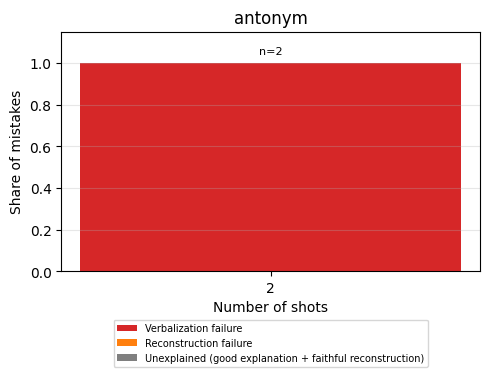

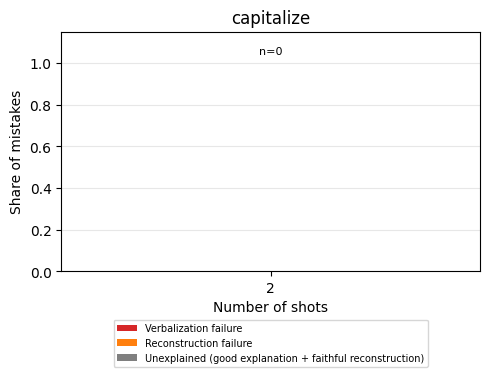

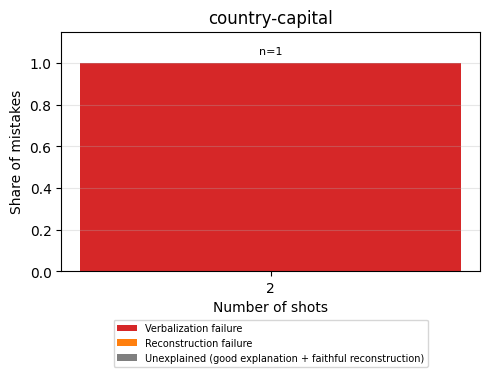

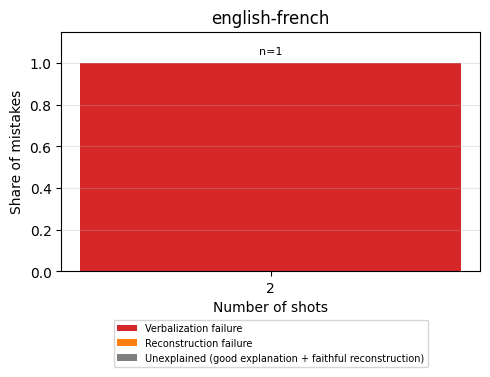

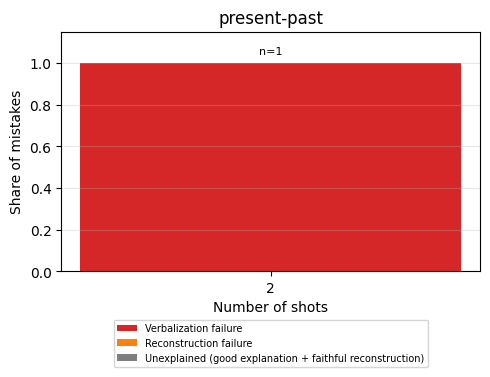

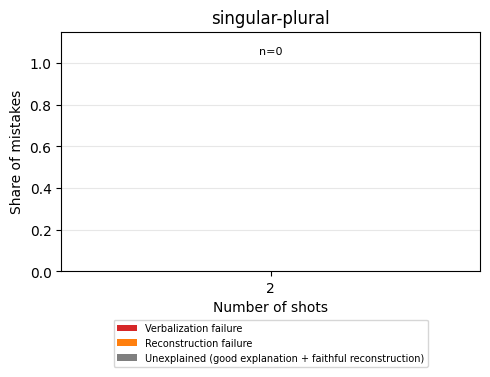

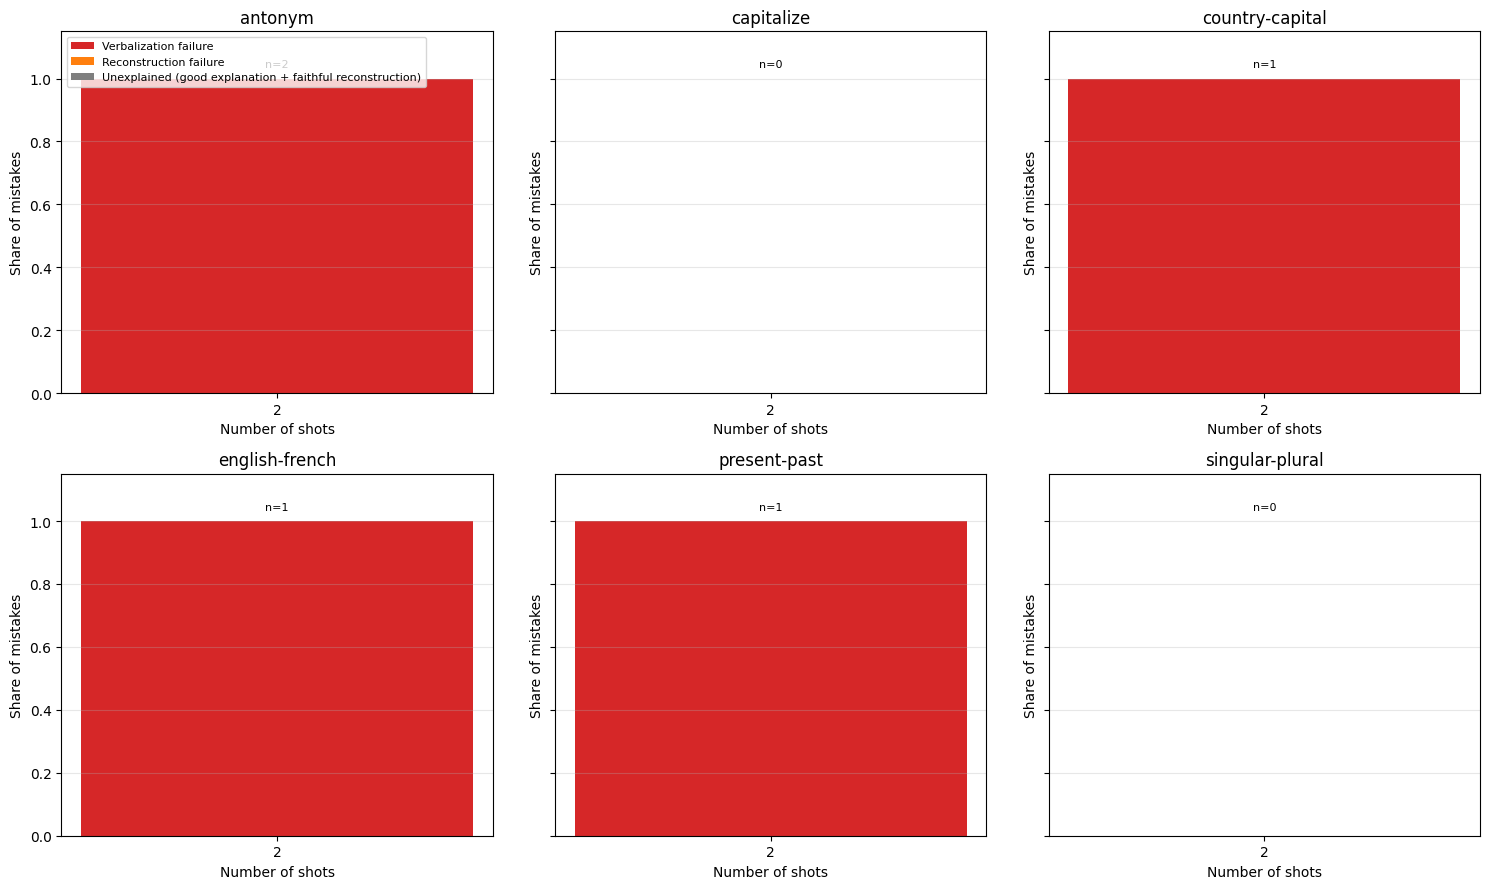

This run's ID: 20260825_035941


In [12]:
"""
Mistake-attribution analysis for the NLA round-trip pipeline on the ICL
function-vector tasks (Todd et al. 2023, arXiv:2310.15213).

For each (task, n_shots) config, this only cares about cases where the
NLA round-trip (h patched with AR(verbalize(h))) gets the WRONG answer.
Correct cases are not scored or stored -- per Pavlos, what's missing is
a breakdown of *why* the mistakes happen, not another accuracy number.

For every mistake we distinguish two failure loci:

  1) verbalization failure -- the AV's natural-language explanation of
     h_orig doesn't actually specify the task. Tested by dropping AR
     entirely and handing the explanation to the model as plain text
     instructions prepended to the ICL prompt (`correct_instructed`).
     If the model still gets it wrong even when just READING the
     explanation, AR never had a chance -- the fault is upstream of it.

  2) reconstruction failure -- the explanation is fine (model gets it
     right when instructed with it directly), but AR failed to encode
     that explanation back into something close to h_orig. Measured
     via cosine similarity between h_orig and h_hat = ar(explanation).

  A case where the explanation is good (correct_instructed=True) AND
  the reconstruction is faithful (sim >= SIM_THRESHOLD) but nla is
  still wrong doesn't fit either bucket -- logged as "unexplained"
  (patching/execution issue, or a genuine ceiling effect).

Notebook cells -- paste/import your existing definitions (av, ar,
run_with_patch, LastTokenPatcher, client, critic, model, tokenizer,
DEVICE) before running this.

Dataset sources, all expected flat under datasets/:
  - antonym:           Nguyen et al. 2017 (AntSynNET) -- github.com/nguyenkh/AntSynNET
  - capitalize:        ChatGPT-generated
  - country-capital:   ChatGPT-generated
  - english-french:    Conneau et al. 2017 (MUSE bilingual dictionaries) --
                        both en-fr.0-5000.txt (train) and en-fr.5000-6500.txt
                        (test) splits, concatenated into one pool
  - present-past:      ChatGPT-generated
  - singular-plural:   ChatGPT-generated
"""

# %%
import json
import random
import string
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

TASKS = [
    "antonym",
    "capitalize",
    "country-capital",
    "english-french",
    "present-past",
    "singular-plural",
]

SHOT_COUNTS = [2]
N_PER_CONFIG = 5
MAX_NEW_TOKENS = 256
SEED = 0

# Cosine-similarity cutoff used to label a reconstruction "faithful" vs
# "diverged" when reporting rates. Kept separate from the raw sim value
# stored per mistake, so you can re-bucket at a different threshold later
# without re-running any model calls.
SIM_THRESHOLD = 0.7

DATA_DIR = Path("datasets")
OUT_DIR = Path("/mnt/ssd-1/soar-nla/kaylee")
CASE_SENSITIVE_TASKS = {"capitalize"}


# %%
# --------------------------------------------------------------------------
# Per-task dataset loaders -- three different source formats, so three loaders
# --------------------------------------------------------------------------

def load_antonym(data_dir: Path, pos_tags=("verb", "noun", "adjective"),
                  splits=("train", "val", "test"),
                  tokenizer=None) -> list[dict]:
    """AntSynNET (Nguyen et al. 2017), antonym pairs only.

    Files are named like 'verb-pairs.train', 'noun-pairs.val',
    'adjective-pairs.test' -- tab-separated: word1, word2, label,
    where label is 1 for antonym pairs and 0 for synonym pairs.

    Combines all POS categories across all splits into one pool,
    keeps only label==1 rows, de-dupes exact (input, output) pairs,
    and -- if a tokenizer is passed -- further filters to pairs where
    BOTH words tokenize as a single token, matching Todd et al. 2023
    (2,398 antonym pairs kept after that step).
    """
    seen = set()
    pairs = []
    for pos in pos_tags:
        for split in splits:
            path = data_dir / f"{pos}-pairs.{split}"
            if not path.exists():
                print(f"[warn] missing file: {path}")
                continue
            with open(path) as f:
                for line in f:
                    parts = line.strip().split("\t")
                    if len(parts) < 3:
                        continue
                    w1, w2, label = parts[0], parts[1], parts[2]
                    if label != "1":          # keep antonyms only, drop synonyms (0)
                        continue
                    key = (w1, w2)
                    if key in seen:
                        continue
                    seen.add(key)
                    pairs.append({"input": w1, "output": w2})

    if tokenizer is not None:
        def is_single_token(word: str) -> bool:
            return len(tokenizer.encode(" " + word, add_special_tokens=False)) == 1
        pairs = [p for p in pairs
                 if is_single_token(p["input"]) and is_single_token(p["output"])]

    return pairs


def load_english_french(paths) -> list[dict]:
    """Conneau et al. 2017 (MUSE) bilingual dictionary format: one
    'english_word french_word' pair per line, whitespace-separated.
    Accepts a single path or a list of paths -- MUSE ships en-fr as
    separate train (0-5000) / test (5000-6500) splits, but nothing in
    this pipeline trains/evaluates a mapping, so both are concatenated
    into one pool rather than kept separate.

    MUSE dictionaries list multiple valid translations for some English
    words (e.g. 'chat' -> 'discuter'/'discussion'/'chat'/...). Only the
    FIRST translation seen for a given English word is kept -- later
    duplicates are dropped -- so every English word maps to exactly one
    canonical French output. This avoids two problems: (a) the same
    input appearing as both a demonstration and the query with
    conflicting gold answers, and (b) is_correct() marking a model's
    valid-but-different translation as wrong non-deterministically.
    """
    if isinstance(paths, (str, Path)):
        paths = [paths]
    seen = {}
    for path in paths:
        with open(path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 2:
                    continue
                en, fr = parts[0], parts[1]
                seen.setdefault(en, fr)
    return [{"input": en, "output": fr} for en, fr in seen.items()]


def load_json_pairs(path: Path) -> list[dict]:
    """ChatGPT-generated tasks (capitalize, country-capital, present-past,
    singular-plural). Expects a JSON list of {"input": ..., "output": ...}.
    """
    with open(path) as f:
        raw = json.load(f)
    if isinstance(raw, dict) and "examples" in raw:
        raw = raw["examples"]
    return [{"input": ex["input"], "output": ex["output"]} for ex in raw]


TASK_LOADERS = {
    "antonym": (load_antonym, None),   # loader takes the data_dir directly
    "capitalize": (load_json_pairs, "capitalize.json"),
    "country-capital": (load_json_pairs, "country-capital.json"),
    "english-french": (load_english_french, ["en-fr.0-5000.txt", "en-fr.5000-6500.txt"]),
    "present-past": (load_json_pairs, "present-past.json"),
    "singular-plural": (load_json_pairs, "singular-plural.json"),
}

def load_fv_task(task_name: str, data_dir: Path = DATA_DIR, tokenizer=None) -> list[dict]:
    loader, rel_path = TASK_LOADERS[task_name]
    if task_name == "antonym":
        return loader(data_dir, tokenizer=tokenizer)
    if isinstance(rel_path, list):
        full_paths = [data_dir / p for p in rel_path]
    else:
        full_paths = data_dir / rel_path
    return loader(full_paths)


# %%
# --------------------------------------------------------------------------
# Prompting / scoring
# --------------------------------------------------------------------------

def build_icl_prompt(pairs: list[dict], query_idx: int, n_shots: int, rng: random.Random,
                      extra_exclude_words: set[str] | None = None) -> tuple[str, str]:
    """Excludes candidate demonstrations by matching INPUT WORD, not just
    index -- keeps the query word out of its own demo pool so nothing
    leaks the answer.
    """
    query_word = pairs[query_idx]["input"]
    excluded_words = {query_word} | (extra_exclude_words or set())
    pool = [i for i in range(len(pairs)) if i != query_idx and pairs[i]["input"] not in excluded_words]
    shot_idxs = rng.sample(pool, min(n_shots, len(pool)))
    lines = [f"Q: {pairs[i]['input']}\nA: {pairs[i]['output']}" for i in shot_idxs]
    lines.append(f"Q: {query_word}\nA:")
    instruction = "Answer with a single word only. No punctuation, no explanation."
    prompt = instruction + "\n\n" + "\n\n".join(lines)
    gold = pairs[query_idx]["output"]
    return prompt, gold


def extract_word_answer(text: str) -> str:
    first_line = text.strip().split("\n")[0]
    return first_line.strip(string.punctuation + " ")


def is_correct(pred: str, gold: str, case_sensitive: bool) -> bool:
    if not case_sensitive:
        pred, gold = pred.lower(), gold.lower()
    return pred == gold


def cosine_sim(h_a: torch.Tensor, h_b: torch.Tensor) -> float:
    # h_a (from run_with_patch, e.g. cuda:3) and h_b (from ar(), which may
    # land on cpu or a different device depending on how that model is
    # placed) aren't guaranteed to already share a device -- unlike
    # run_with_patch(patch_vec=...), which presumably handles that
    # internally when it injects the vector, this is a direct op, so it
    # needs an explicit .to() or it throws a device-mismatch RuntimeError.
    h_b = h_b.to(h_a.device)
    return torch.nn.functional.cosine_similarity(
        h_a.flatten().float(), h_b.flatten().float(), dim=0
    ).item()


def classify_mistake(correct_instructed: bool, sim: float, sim_threshold: float = SIM_THRESHOLD) -> str:
    """Buckets one NLA mistake into a failure locus.

    - not correct_instructed          -> explanation itself doesn't
                                          specify the task; AR never had
                                          a shot at it.
    - correct_instructed, sim < thr   -> explanation was fine, AR failed
                                          to encode it faithfully.
    - correct_instructed, sim >= thr  -> explanation good, reconstruction
                                          faithful, still wrong -- not
                                          attributable to either AV or AR
                                          (patching/execution issue, or a
                                          genuine ceiling effect).
    """
    if not correct_instructed:
        return "verbalization_failure"
    if sim < sim_threshold:
        return "reconstruction_failure"
    return "unexplained"


# %%
# --------------------------------------------------------------------------
# One (task, n_shots) configuration
# --------------------------------------------------------------------------

def run_mistake_analysis(task_name: str, n_shots: int, pairs: list[dict],
                          rng: random.Random, verbose: bool = False) -> dict:
    """Runs the NLA round-trip on N_PER_CONFIG samples. Only mistakes
    (nla prediction wrong) get the follow-up diagnostic calls; correct
    cases are counted but otherwise discarded immediately.
    """
    n = min(N_PER_CONFIG, len(pairs))
    query_idxs = rng.sample(range(len(pairs)), n)
    case_sensitive = task_name in CASE_SENSITIVE_TASKS

    mistakes = []

    if verbose:
        print(f"\n{'=' * 70}")
        print(f"CONFIG: task={task_name!r}  n_shots={n_shots}  n={n}")
        print(f"{'=' * 70}")

    for i, qi in enumerate(query_idxs):
        prompt, gold = build_icl_prompt(pairs, qi, n_shots, rng)

        _, h_orig = run_with_patch(prompt, patch_vec=None, max_new_tokens=MAX_NEW_TOKENS)
        explanation = av(h_orig)
        h_hat = ar(explanation)
        # ar() isn't guaranteed to land on the same device h_orig came from
        # (e.g. if the AR model is placed differently than the target
        # model) -- normalize once here so every downstream use (patching
        # AND cosine_sim below) is consistent instead of hitting a
        # cuda:N/cpu mismatch partway through.
        h_hat = h_hat.to(h_orig.device)

        text_nla, _ = run_with_patch(prompt, patch_vec=h_hat, max_new_tokens=MAX_NEW_TOKENS)
        pred_nla = extract_word_answer(text_nla)
        correct_nla = is_correct(pred_nla, gold, case_sensitive)

        if correct_nla:
            if verbose:
                print(f"  sample {i + 1}/{n}: correct, skipping")
            continue

        # -- mistake found: run the diagnostics --

        # 1) verbalization check: hand the explanation to the model as
        #    plain-text instructions, no AR/patching involved at all.
        instructed_prompt = f"{explanation}\n\n{prompt}"
        text_instructed, _ = run_with_patch(instructed_prompt, patch_vec=None, max_new_tokens=MAX_NEW_TOKENS)
        pred_instructed = extract_word_answer(text_instructed)
        correct_instructed = is_correct(pred_instructed, gold, case_sensitive)

        # 2) reconstruction check: how close did AR's h_hat land to h_orig.
        sim = cosine_sim(h_orig, h_hat)

        locus = classify_mistake(correct_instructed, sim)

        record = {
            "task": task_name,
            "n_shots": n_shots,
            "query_input": pairs[qi]["input"],
            "gold": gold,
            "pred_nla": pred_nla,
            "explanation": explanation,
            "correct_instructed": correct_instructed,
            "pred_instructed": pred_instructed,
            "sim_h_orig_h_hat": sim,
            "failure_locus": locus,
        }
        mistakes.append(record)

        if verbose:
            print(f"  sample {i + 1}/{n}: MISTAKE  gold={gold!r} pred_nla={pred_nla!r}")
            print(f"    correct_instructed={correct_instructed}  sim={sim:.3f}  -> {locus}")

    n_mistakes = len(mistakes)
    n_verbalization = sum(1 for m in mistakes if m["failure_locus"] == "verbalization_failure")
    n_reconstruction = sum(1 for m in mistakes if m["failure_locus"] == "reconstruction_failure")
    n_unexplained = sum(1 for m in mistakes if m["failure_locus"] == "unexplained")

    def rate(k):
        return k / n_mistakes if n_mistakes else float("nan")

    if verbose:
        print(f"\n{'-' * 70}")
        print(f"SUMMARY  task={task_name!r}  n_shots={n_shots}")
        print(f"  n_total = {n}   n_mistakes = {n_mistakes}")
        print(f"  verbalization_failure_rate  = {rate(n_verbalization):.3f}  ({n_verbalization}/{n_mistakes})")
        print(f"  reconstruction_failure_rate = {rate(n_reconstruction):.3f}  ({n_reconstruction}/{n_mistakes})")
        print(f"  unexplained_rate            = {rate(n_unexplained):.3f}  ({n_unexplained}/{n_mistakes})")
        print(f"{'-' * 70}\n")

    return {
        "task": task_name,
        "n_shots": n_shots,
        "n_total": n,
        "n_mistakes": n_mistakes,
        "n_verbalization_failure": n_verbalization,
        "n_reconstruction_failure": n_reconstruction,
        "n_unexplained": n_unexplained,
        "verbalization_failure_rate": rate(n_verbalization),
        "reconstruction_failure_rate": rate(n_reconstruction),
        "unexplained_rate": rate(n_unexplained),
        "mistakes": mistakes,
    }


# %%
# --------------------------------------------------------------------------
# Sweep + plotting
# --------------------------------------------------------------------------
#
# One DataFrame per task, saved to its own CSV the moment that task
# finishes -- not batched up into one big dict/JSON at the end. If task 4
# of 6 throws (OOM, a bad dataset file, whatever), tasks 1-3 are already
# on disk as nla_mistake_attribution_<task>_<run_id>.csv and
# load_sweep_results() below can pull them back in for plotting without
# rerunning anything. The sweep also catches per-task exceptions and moves
# on to the next task rather than aborting the whole run.
#
# The per-mistake records (query, gold, explanation, sim, failure_locus,
# etc.) don't belong in that summary CSV -- they're variable-length and
# meant for qualitative spot-checking, not plotting -- so they're saved
# separately, one JSON per task, alongside the CSV.

# Rate column -> (color, label) used by both plotting loops below. Single
# source of truth so per-task and combined-grid plots can't drift out of
# sync with each other. Order matters: this is stack order, bottom to top.
RATE_COLUMNS = [
    ("verbalization_failure_rate", "tab:red", "Verbalization failure"),
    ("reconstruction_failure_rate", "tab:orange", "Reconstruction failure"),
    ("unexplained_rate", "tab:gray", "Unexplained (good explanation + faithful reconstruction)"),
]


def run_sweep(run_id: str | None = None) -> tuple[dict[str, pd.DataFrame], str]:
    if run_id is None:
        run_id = datetime.now().strftime("%Y%m%d_%H%M%S")

    rng = random.Random(SEED)
    results: dict[str, pd.DataFrame] = {}
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    for task_name in TASKS:
        try:
            pairs = load_fv_task(task_name)
            rows = []
            task_mistakes = []
            for k in tqdm(SHOT_COUNTS, desc=task_name, unit="shot-count"):
                result = run_mistake_analysis(task_name, k, pairs, rng, verbose=True)
                task_mistakes.extend(result.pop("mistakes"))  # keep out of the summary row
                rows.append(result)
        except Exception as e:
            print(f"[error] task {task_name!r} failed, skipping it and continuing: {e!r}")
            continue

        df = pd.DataFrame(rows)
        results[task_name] = df

        csv_path = OUT_DIR / f"nla_mistake_attribution_{task_name}_{run_id}.csv"
        try:
            df.to_csv(csv_path, index=False)
            print(f"[ok] {task_name} -> {csv_path}")
        except OSError as e:
            print(f"[warn] ran {task_name} but could not save its CSV: {e}")

        mistakes_path = OUT_DIR / f"nla_mistake_attribution_mistakes_{task_name}_{run_id}.json"
        try:
            with open(mistakes_path, "w") as f:
                json.dump(task_mistakes, f, indent=2)
            print(f"[ok] mistakes -> {mistakes_path}")
        except OSError as e:
            print(f"[warn] ran {task_name} but could not save its mistakes JSON: {e}")

    return results, run_id


def load_sweep_results(run_id: str, tasks: list[str] = TASKS) -> dict[str, pd.DataFrame]:
    """Reload whatever per-task CSVs already exist on disk for a given
    run_id -- e.g. after a kernel crash mid-sweep, or if you just want to
    replot without rerunning the model. Silently skips tasks that never
    finished/saved.
    """
    results: dict[str, pd.DataFrame] = {}
    for task_name in tasks:
        csv_path = OUT_DIR / f"nla_mistake_attribution_{task_name}_{run_id}.csv"
        if csv_path.exists():
            results[task_name] = pd.read_csv(csv_path)
        else:
            print(f"[warn] no cached CSV for {task_name} at {csv_path}")
    return results


def _stacked_failure_bars(ax, df: pd.DataFrame, title: str):
    """Draws one stacked bar per n_shots value: the three failure-locus
    rates, which sum to 1 of the mistakes at that shot count. n_mistakes
    is annotated above each bar since these are rates of a sample that
    can get quite small at high shot counts (where accuracy climbs and
    mistakes get rarer) -- a rate on its own hides that.
    """
    x = df["n_shots"].to_numpy()
    width = (np.diff(sorted(set(x))).min() * 0.6) if len(set(x)) > 1 else 0.6
    bottom = np.zeros(len(df))
    for col, color, label in RATE_COLUMNS:
        if col not in df.columns:
            print(f"[warn] missing column {col!r}, skipping that segment")
            continue
        vals = df[col].fillna(0).to_numpy()
        ax.bar(x, vals, bottom=bottom, width=width, color=color, label=label)
        bottom += vals

    for xi, n_mistakes in zip(x, df["n_mistakes"]):
        ax.text(xi, 1.03, f"n={n_mistakes}", ha="center", va="bottom", fontsize=8)

    ax.set_xlabel("Number of shots")
    ax.set_ylabel("Share of mistakes")
    ax.set_ylim(0, 1.15)
    ax.set_xticks(sorted(set(x)))
    ax.set_title(title)
    ax.grid(alpha=0.3, axis="y")


def plot_sweep(results: dict[str, pd.DataFrame], run_id: str):
    OUT_DIR.mkdir(parents=True, exist_ok=True)

    for task_name, df in results.items():
        fig, ax = plt.subplots(figsize=(5, 4))
        _stacked_failure_bars(ax, df, task_name)
        ax.legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=1)
        fig.tight_layout()
        fig.savefig(OUT_DIR / f"nla_mistake_attribution_{task_name}_{run_id}.png", dpi=150,
                    bbox_inches="tight")
        plt.show()

    fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharey=True)
    for ax, task_name in zip(axes.flat, TASKS):
        if task_name not in results:
            ax.set_title(f"{task_name} (no data)")
            ax.axis("off")
            continue
        _stacked_failure_bars(ax, results[task_name], task_name)
    handled_axes = [ax for ax in axes.flat if ax.patches]
    if handled_axes:
        handled_axes[0].legend(fontsize=8, loc="upper left")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"nla_mistake_attribution_all_tasks_{run_id}.png", dpi=150)
    plt.show()


results, run_id = run_sweep()
plot_sweep(results, run_id)
print(f"This run's ID: {run_id}")

- might have to loosen to check if word is there or not instead of expecting exact output
- The av/ar round-trip through natural language seems to preserve the subject matter far more reliably than it preserves what specifically to do with that subject — the fine-grained target word, or the task's input→output mapping. That's a meaningful and fairly interpretable finding for whatever you're writing up, distinct from just "accuracy is low."

## Cleanup

Close the AV client's HTTP session and stop SGLang only if this notebook launched it. An AV server that was already running before the notebook is left untouched.


In [13]:
if "client" in globals() and hasattr(client, "_http"):
    client._http.close()
    print("Closed NLA client HTTP session")

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

if "sglang_proc" in globals() and sglang_proc is not None:
    sglang_proc.terminate()
    sglang_proc.wait(timeout=30)
    print("Stopped SGLang launched by this notebook")
else:
    print("No SGLang subprocess launched by this notebook")

# Optional final memory check:
# !nvidia-smi

Closed NLA client HTTP session
No SGLang subprocess launched by this notebook
